# Punto 1 — Clasificación de transacciones fraudulentas

## 2. Selección de características y evaluación de modelos

### Objetivo

Comparar diferentes estrategias de selección de características y evaluar **32 configuraciones** de aprendizaje supervisado para identificar transacciones fraudulentas en `creditcard.csv`.

El notebook presenta los resultados ya obtenidos en el proyecto y explica **qué significan y por qué pudieron generarse**. No vuelve a entrenar los modelos: recupera los archivos producidos por los programas de `src/punto_1/`.

### Actividades

- Revisar la selección por correlación y por PCA.
- Comprender la validación cruzada estratificada.
- Comparar las 32 configuraciones y las cuatro familias de algoritmos.
- Examinar las cinco mejores configuraciones.
- Interpretar la evaluación final y las matrices de confusión.
- Redactar las conclusiones del punto 1.

> **Convención:** clase `0` = transacción legítima; clase `1` = fraude. Todas las métricas se leen de los archivos del proyecto, excepto la tabla ilustrativa de correlaciones, cuyos valores se registraron en la exploración anterior.

## 1. Configuración del entorno

Usamos el mismo entorno virtual del notebook `01_exploracion_fraude.ipynb`. Como este notebook está dentro de `notebooks/`, localizamos automáticamente la raíz del proyecto para importar clases y leer resultados. **No es necesario copiar los archivos `.py` a este notebook.**

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Encontrar la raíz tanto si Jupyter abre en notebooks/ como en la raíz.
ubicacion = Path.cwd().resolve()
RAIZ = next(
    (
        carpeta
        for carpeta in [ubicacion, *ubicacion.parents]
        if (carpeta / "src" / "punto_1").is_dir()
    ),
    None
)
if RAIZ is None:
    raise RuntimeError(
        "No se encontró la carpeta src/punto_1. "
        "Abre el proyecto Proyecto_Machine_Learning en VS Code."
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

RESULTADOS = RAIZ / "resultados" / "punto_1"
print("Proyecto:", RAIZ)
print("Python:", sys.executable)
print("Resultados:", RESULTADOS)

Proyecto: C:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning
Python: c:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning\.venv\Scripts\python.exe
Resultados: C:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning\resultados\punto_1


## 2. Recordatorio: características y desbalance

En el primer notebook se identificaron **284.807 transacciones**, de las cuales solo **492** eran fraudulentas (**0,173 %**). Se reservaron **227.845** registros para entrenamiento y **56.962** para prueba.

Esto condiciona toda la evaluación: un clasificador que predijera «legítima» para todas las transacciones obtendría más del 99 % de exactitud, pero no identificaría ningún fraude.

Por eso, la métrica principal para seleccionar configuraciones es **F1 macro**, que promedia el F1 de ambas clases sin ponderarlo por su frecuencia. También revisamos la **sensibilidad de fraude**, la **precisión de fraude** y la matriz de confusión.

## 3. Selección de características: correlación y PCA

### Selección por correlación

Se conservaron **20 variables originales** relacionadas con la clase objetivo. Este procedimiento facilita la interpretación, porque los modelos siguen trabajando con características existentes.

Los siguientes valores de correlación absoluta se registraron durante la exploración del proyecto. Se muestran los diez más destacados; **la correlación no demuestra causalidad**.

,Característica,Correlación absoluta
0,V17,0.3219
1,V14,0.3011
2,V12,0.2600
3,V10,0.2179
4,V3,0.1941
5,V16,0.1938
6,V7,0.1862
7,V11,0.1537
8,V4,0.1350
9,V18,0.1087


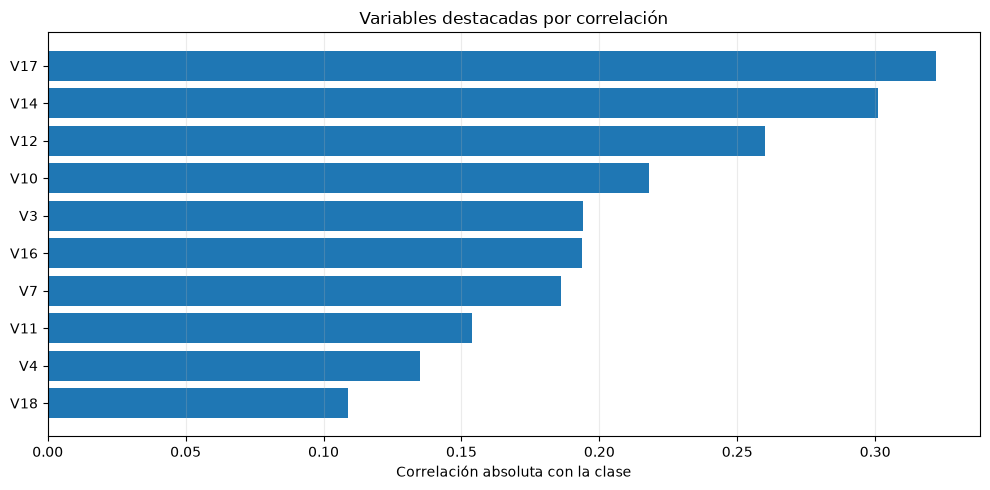

In [2]:
# Resumen de la exploración de correlaciones ya realizada.
correlaciones = pd.DataFrame({
    "Característica": ["V17", "V14", "V12", "V10", "V3", "V16", "V7", "V11", "V4", "V18"],
    "Correlación absoluta": [0.3219, 0.3011, 0.2600, 0.2179, 0.1941, 0.1938, 0.1862, 0.1537, 0.1350, 0.1087]
})
display(correlaciones)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(correlaciones["Característica"][::-1], correlaciones["Correlación absoluta"][::-1])
ax.set_xlabel("Correlación absoluta con la clase")
ax.set_title("Variables destacadas por correlación")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Análisis de componentes principales (PCA)

PCA transforma las variables originales en **componentes que resumen su variabilidad**. En nuestros experimentos, el criterio de conservar al menos el 95 % de la varianza produjo **27 componentes**, con aproximadamente **95,57 %** de variabilidad explicada.

**¿Por qué el resultado puede diferir entre correlación y PCA?**

La correlación prioriza asociaciones individuales con la clase, mientras que PCA prioriza direcciones de alta varianza **sin usar la clase objetivo**. Por tanto, conservar mucha varianza no implica necesariamente conservar toda la información útil para detectar fraudes raros.

En los pipelines de validación cruzada, el escalado y la selección de características se ajustaron **dentro de cada fold** para evitar fuga de información desde validación hacia entrenamiento.

In [3]:
resumen_seleccion = pd.DataFrame({
    "Método": ["Correlación", "PCA"],
    "Variables de salida": [20, 27],
    "Criterio": ["Asociación con Class", "Al menos 95 % de varianza"],
    "Interpretación": ["Conserva variables originales", "Genera componentes nuevos"]
})
display(resumen_seleccion)

,Método,Variables de salida,Criterio,Interpretación
0,Correlación,20,Asociación con Class,Conserva variables originales
1,PCA,27,Al menos 95 % de varianza,Genera componentes nuevos


## 4. Configuración de los 32 experimentos

Se combinaron **cuatro familias de algoritmos**, **dos estrategias de transformación** y **cuatro configuraciones de hiperparámetros** por familia:

**4 familias × 2 selecciones × 4 variantes = 32 configuraciones.**

- **Regresión logística:** modelo lineal que estima probabilidades mediante una función sigmoide.
- **SVM lineal:** busca una frontera separadora con margen amplio.
- **Árbol de decisión:** aprende reglas de partición no lineales.
- **Red neuronal MLP:** aprende combinaciones no lineales de características.

El entrenamiento se realizó previamente con `python -m src.punto_1.validacion_cruzada --modelo ...`. Este notebook **lee** los resultados, no ejecuta de nuevo las 32 validaciones.

In [4]:
ruta_cv = RESULTADOS / "validacion_cruzada.csv"
if not ruta_cv.is_file():
    raise FileNotFoundError(
        f"No existe {ruta_cv}. Primero ejecuta los cuatro comandos "
        "de validacion_cruzada del punto 1."
    )

# Reutilizamos la función de análisis que ya existe en src/punto_1.
from src.punto_1.analizar_top5 import cargar_ranking

ranking_cv = cargar_ranking(cv_folds=3)
print("Configuraciones registradas:", len(ranking_cv))
print("Folds por configuración: 3")
display(ranking_cv[[
    "modelo_id", "modelo", "seleccion", "cv_folds", "f1_macro", "f1_macro_std", "sensibilidad_fraude"
]].head(10).round(4))

print("\nCombinaciones por familia y selección:")
display(pd.crosstab(ranking_cv["modelo"], ranking_cv["seleccion"]))

Configuraciones registradas: 32
Folds por configuración: 3


,modelo_id,modelo,seleccion,cv_folds,f1_macro,f1_macro_std,sensibilidad_fraude
0,red_neuronal_pca_02,red_neuronal,pca,3,0.9174,0.0146,0.7616
1,red_neuronal_correlacion_02,red_neuronal,correlacion,3,0.9154,0.0109,0.7641
2,red_neuronal_correlacion_01,red_neuronal,correlacion,3,0.9142,0.0048,0.7665
3,red_neuronal_pca_03,red_neuronal,pca,3,0.9135,0.0064,0.7487
4,red_neuronal_pca_01,red_neuronal,pca,3,0.9125,0.0029,0.7615
5,red_neuronal_correlacion_04,red_neuronal,correlacion,3,0.9122,0.0020,0.7817
6,red_neuronal_correlacion_03,red_neuronal,correlacion,3,0.9057,0.0147,0.7208
7,red_neuronal_pca_04,red_neuronal,pca,3,0.8992,0.0122,0.7564
8,arbol_correlacion_04,arbol,correlacion,3,0.7616,0.0468,0.7918
9,arbol_pca_04,arbol,pca,3,0.6801,0.0580,0.7664



Combinaciones por familia y selección:


seleccion,correlacion,pca
modelo,,
arbol,4,4
logistica,4,4
red_neuronal,4,4
svm,4,4


## 5. ¿Cómo funcionó la validación cruzada?

En la validación cruzada estratificada de **tres folds**, cada configuración se entrenó tres veces: en cada repetición se ajustó con una parte del conjunto de entrenamiento y se evaluó con otra parte no usada en ese ajuste.

Se promediaron las métricas entre folds y se calculó una desviación estándar del F1 macro. Esta estrategia reduce la dependencia de una única partición y conserva la proporción de fraudes en cada fold.

**Criterio de selección:** ordenar las configuraciones por `f1_macro` promedio y usar la sensibilidad de fraude como criterio secundario en caso de empate. El conjunto de prueba final todavía no interviene.

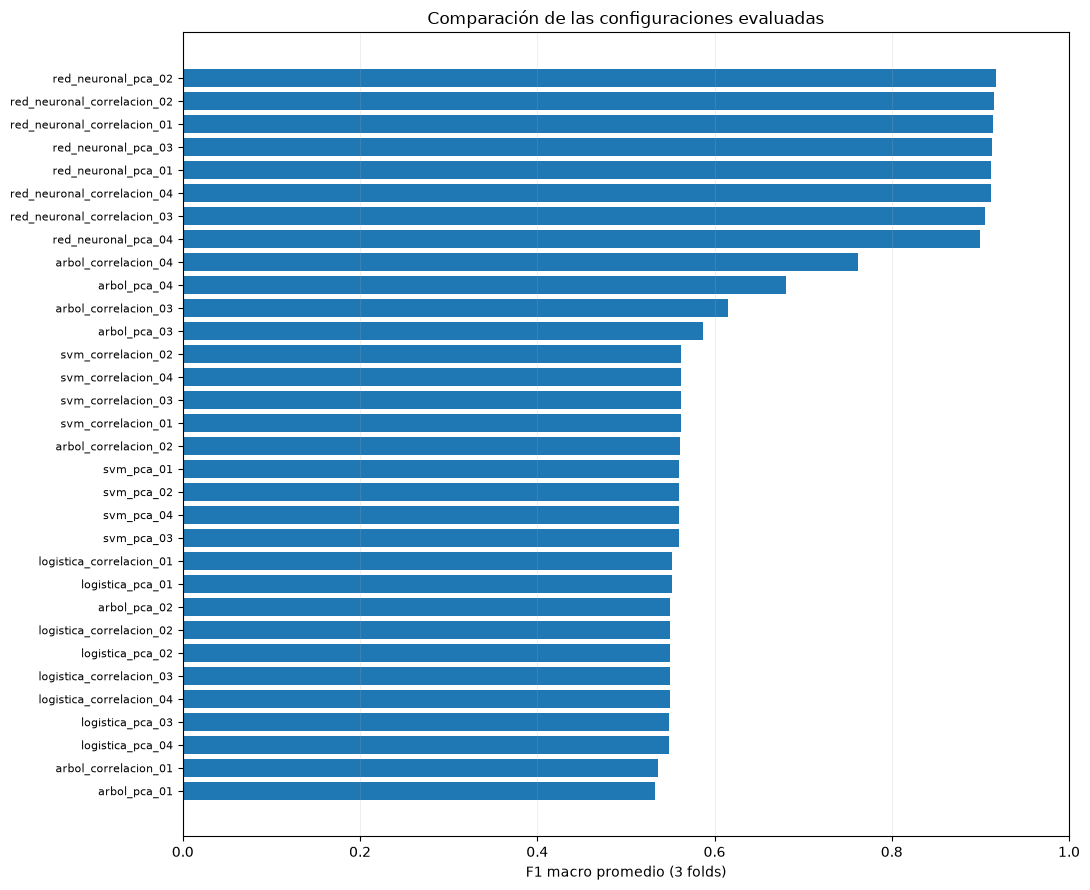

In [5]:
familias = {
    "logistica": "Regresión logística",
    "svm": "SVM lineal",
    "arbol": "Árbol de decisión",
    "red_neuronal": "Red neuronal MLP",
}

ranking_cv["familia_legible"] = ranking_cv["modelo"].map(familias).fillna(ranking_cv["modelo"])

# La gráfica presenta las 32 configuraciones reales ordenadas por F1 macro.
orden = ranking_cv.sort_values("f1_macro", ascending=True)
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(orden["modelo_id"], orden["f1_macro"])
ax.set_xlabel("F1 macro promedio (3 folds)")
ax.set_title("Comparación de las configuraciones evaluadas")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.2)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### Interpretación general

La gráfica permite identificar qué configuraciones lograron un **equilibrio entre el rendimiento de transacciones legítimas y fraudulentas**. Como las clases están muy desbalanceadas, pequeñas diferencias en falsos positivos o falsos negativos pueden cambiar notablemente la precisión de fraude y, por tanto, el F1 macro.

**Importante:** una barra alta no significa necesariamente que se detectaron todos los fraudes; revisaremos también la sensibilidad específica de la clase minoritaria.

## 6. Comparación entre familias de algoritmos

Tomamos la **mejor configuración por F1 macro** de cada familia para comparar sus capacidades bajo las condiciones evaluadas. No estamos afirmando que una familia sea universalmente superior: la comparación depende de los hiperparámetros, la selección de características y los datos disponibles.

,familia_legible,modelo_id,f1_macro,f1_macro_std,sensibilidad_fraude
0,Red neuronal MLP,red_neuronal_pca_02,0.9174,0.0146,0.7616
8,Árbol de decisión,arbol_correlacion_04,0.7616,0.0468,0.7918
12,SVM lineal,svm_correlacion_02,0.5621,0.0083,0.8985
21,Regresión logística,logistica_correlacion_01,0.5517,0.0055,0.9010


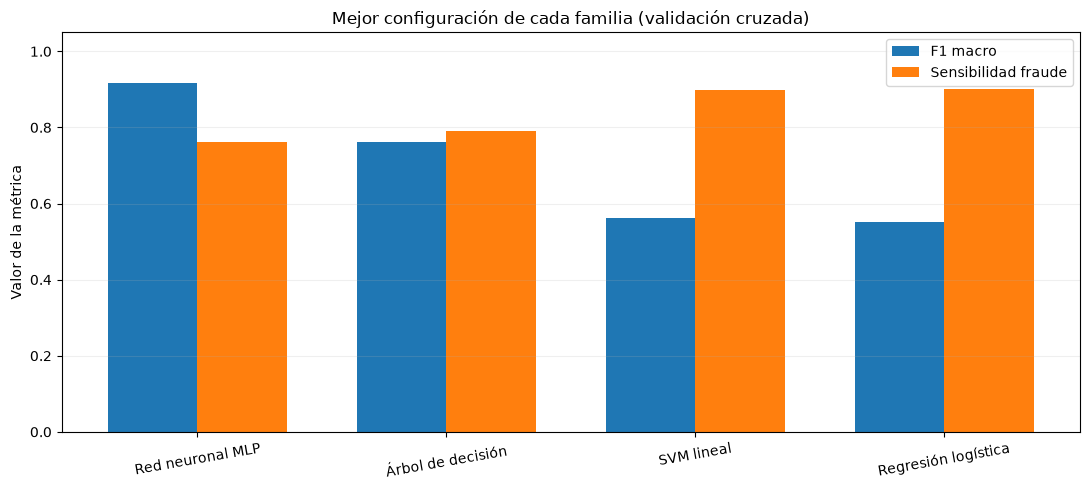

In [6]:
mejor_por_familia = (
    ranking_cv.sort_values(["f1_macro", "sensibilidad_fraude"], ascending=False)
    .drop_duplicates(subset="modelo", keep="first")
    .copy()
)
display(mejor_por_familia[[
    "familia_legible", "modelo_id", "f1_macro", "f1_macro_std", "sensibilidad_fraude"
]].round(4))

x = np.arange(len(mejor_por_familia))
ancho = 0.36
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - ancho / 2, mejor_por_familia["f1_macro"], ancho, label="F1 macro")
ax.bar(x + ancho / 2, mejor_por_familia["sensibilidad_fraude"], ancho, label="Sensibilidad fraude")
ax.set_xticks(x, mejor_por_familia["familia_legible"], rotation=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Mejor configuración de cada familia (validación cruzada)")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### ¿Por qué pueden diferir los resultados?

- **Redes neuronales:** pueden aprender relaciones no lineales entre características y reconocer patrones que las fronteras lineales no capturan. Esto **podría** contribuir a su ventaja observada, aunque la arquitectura y la configuración también influyen.
- **Regresión logística y SVM lineal:** una frontera lineal puede resultar insuficiente si las diferencias entre transacciones fraudulentas y legítimas dependen de interacciones complejas. Además, una sensibilidad alta puede lograrse a costa de muchas falsas alarmas.
- **Árbol de decisión:** representa relaciones no lineales, pero su calidad depende de la profundidad y puede verse afectada por la poca cantidad de ejemplos fraudulentos.

Estas son **interpretaciones plausibles**, no pruebas causales de por qué un algoritmo superó a otro.

## 7. Análisis de las cinco mejores configuraciones

Extraemos el **Top 5 por F1 macro promedio** obtenido mediante validación cruzada. Añadimos la desviación estándar entre folds para observar la variabilidad de cada configuración.

,modelo_id,seleccion,f1_macro,f1_macro_std,sensibilidad_fraude
0,red_neuronal_pca_02,pca,0.9174,0.0146,0.7616
1,red_neuronal_correlacion_02,correlacion,0.9154,0.0109,0.7641
2,red_neuronal_correlacion_01,correlacion,0.9142,0.0048,0.7665
3,red_neuronal_pca_03,pca,0.9135,0.0064,0.7487
4,red_neuronal_pca_01,pca,0.9125,0.0029,0.7615


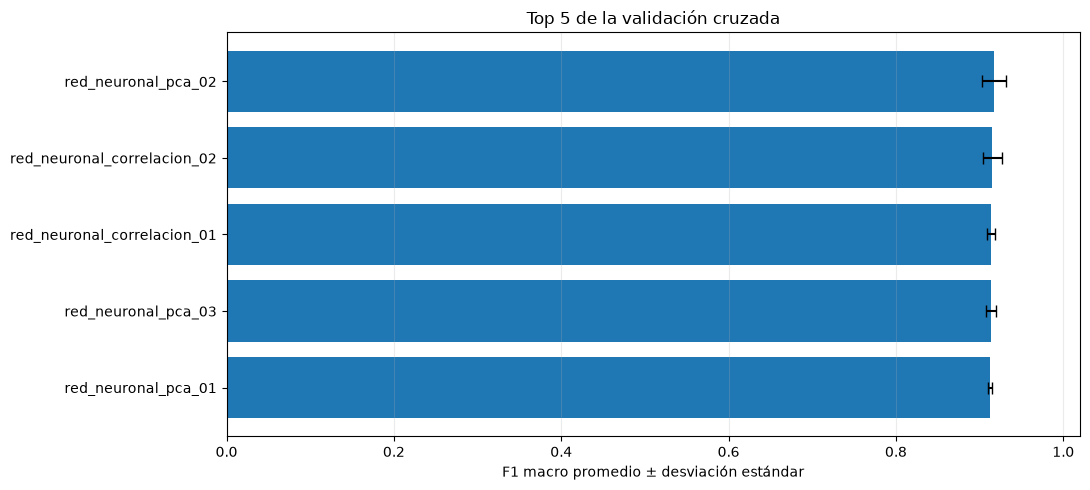

In [7]:
top5 = ranking_cv.head(5).copy()
display(top5[[
    "modelo_id", "seleccion", "f1_macro", "f1_macro_std", "sensibilidad_fraude"
]].round(4))

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top5["modelo_id"][::-1], top5["f1_macro"][::-1],
        xerr=top5["f1_macro_std"][::-1], capsize=4)
ax.set_xlim(0, 1.02)
ax.set_xlabel("F1 macro promedio ± desviación estándar")
ax.set_title("Top 5 de la validación cruzada")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretación del Top 5

En la ejecución documentada, las cinco mejores configuraciones correspondieron a **redes neuronales**. El modelo `red_neuronal_pca_02` obtuvo un F1 macro promedio de **0,9174** con desviación estándar de **0,0146**.

No obstante, su sensibilidad promedio al fraude fue aproximadamente **0,7616**: un F1 macro alto puede coexistir con fraudes que no se detectan. Esto ocurre porque F1 macro combina el rendimiento de ambas clases y no equivale a sensibilidad de fraude.

La proximidad entre los F1 de varias redes sugiere que, con estos datos y configuraciones, **más de una combinación de arquitectura y transformación** puede resultar competitiva.

## 8. Matriz de confusión acumulada de validación cruzada

La matriz del modelo mejor clasificado por F1 macro contiene las predicciones realizadas **fuera de muestra en los folds**. Así podemos leer directamente:

- **VN:** transacciones legítimas reconocidas correctamente.
- **FP:** transacciones legítimas señaladas como fraude (falsas alarmas).
- **FN:** fraudes no identificados.
- **VP:** fraudes detectados.

Estos conteos pertenecen a la validación cruzada; **no son todavía los de la prueba final**.

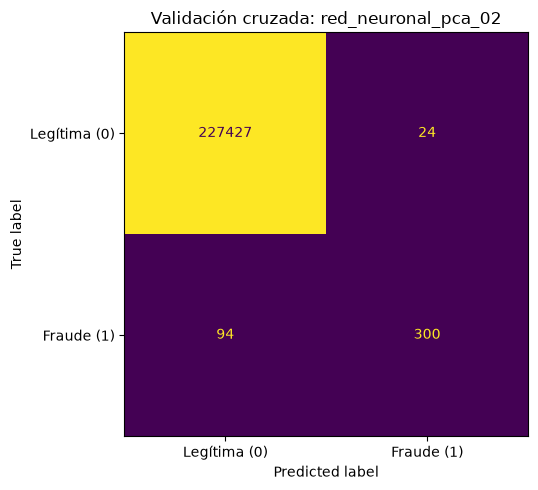

VN, FP, FN, VP: 227427 24 94 300


In [8]:
mejor_cv = ranking_cv.iloc[0]
matriz_cv = np.array([
    [int(mejor_cv["verdaderos_negativos"]), int(mejor_cv["falsos_positivos"])],
    [int(mejor_cv["falsos_negativos"]), int(mejor_cv["verdaderos_positivos"])],
])
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_cv,
    display_labels=["Legítima (0)", "Fraude (1)"]
).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title(f"Validación cruzada: {mejor_cv['modelo_id']}")
plt.tight_layout()
plt.show()

print("VN, FP, FN, VP:", *[int(x) for x in matriz_cv.ravel()])

## 9. Evaluación final sobre el conjunto de prueba reservado

La selección de finalistas se realizó **solo con validación cruzada**: el Top 5 general más el mejor representante de cada familia distinta. Después se ajustó cada pipeline con los **227.845** registros de entrenamiento y se evaluó en los **56.962** registros de prueba, incluidos **98 fraudes**.

La evaluación final debe interpretarse como una comprobación independiente. **No usamos su F1 para escoger nuevos hiperparámetros.**

In [9]:
ruta_final = RESULTADOS / "evaluacion_final" / "metricas_prueba_final.csv"
if not ruta_final.is_file():
    raise FileNotFoundError(
        f"No existe {ruta_final}. Ejecuta previamente "
        "python -m src.punto_1.evaluacion_final"
    )

prueba = pd.read_csv(ruta_final)
prueba = prueba.drop_duplicates(subset="modelo_id", keep="last")

columnas_prueba = [
    "modelo_id", "grupo_comparacion", "f1_macro_cv", "f1_macro",
    "precision_fraude", "sensibilidad_fraude", "falsos_positivos", "falsos_negativos"
]
display(prueba[columnas_prueba].round(4))

# Orden fijado por validación cruzada (evita reordenar por resultados de prueba).
orden_cv = {ident: i for i, ident in enumerate(ranking_cv["modelo_id"])}
prueba["orden_cv"] = prueba["modelo_id"].map(orden_cv)
prueba = prueba.sort_values("orden_cv")

,modelo_id,grupo_comparacion,f1_macro_cv,f1_macro,precision_fraude,sensibilidad_fraude,falsos_positivos,falsos_negativos
0,red_neuronal_pca_02,Top 5,0.9174,0.9085,0.8636,0.7755,12,22
1,red_neuronal_correlacion_02,Top 5,0.9154,0.9009,0.8427,0.7653,14,23
2,red_neuronal_correlacion_01,Top 5,0.9142,0.9028,0.7864,0.8265,22,17
3,red_neuronal_pca_03,Top 5,0.9135,0.9183,0.8953,0.7857,9,21
4,red_neuronal_pca_01,Top 5,0.9125,0.9030,0.8280,0.7857,16,21
5,logistica_correlacion_01,Representante de familia,0.5517,0.5493,0.0593,0.9286,1443,7
6,svm_correlacion_02,Representante de familia,0.5621,0.5611,0.0715,0.9184,1169,8
7,arbol_correlacion_04,Representante de familia,0.7616,0.6925,0.2548,0.8061,231,19


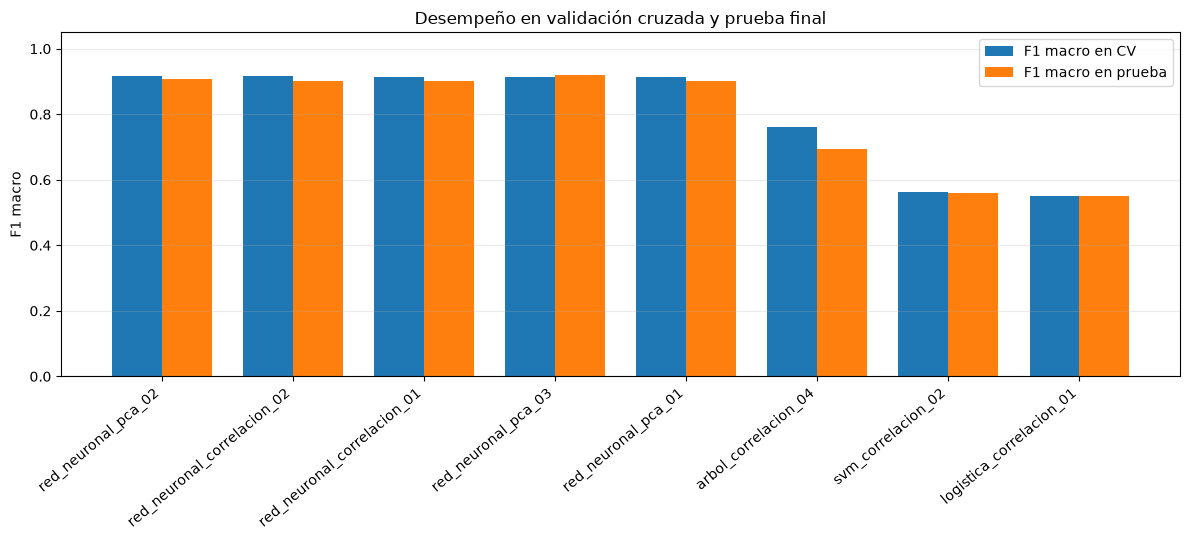

In [10]:
# Gráfica de generalización: F1 CV frente a F1 en prueba.
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(prueba))
ancho = 0.38
ax.bar(x - ancho / 2, prueba["f1_macro_cv"], ancho, label="F1 macro en CV")
ax.bar(x + ancho / 2, prueba["f1_macro"], ancho, label="F1 macro en prueba")
ax.set_xticks(x, prueba["modelo_id"], rotation=40, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 macro")
ax.set_title("Desempeño en validación cruzada y prueba final")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### ¿Cómo interpretar diferencias entre CV y prueba?

Una diferencia puede surgir porque el conjunto de prueba contiene transacciones distintas y **solo 98 fraudes**. Con tan pocos positivos, un puñado de cambios en los falsos negativos altera la sensibilidad y el F1 de fraude.

En la ejecución original, `red_neuronal_pca_02` (elegida por CV) alcanzó **F1 macro = 0,9085** en prueba. Otra configuración, `red_neuronal_pca_03`, registró **0,9183** en prueba, pero **no debemos usar ese resultado para cambiar la configuración previamente seleccionada**, porque implicaría utilizar la prueba como mecanismo de selección.

## 10. Comparación de errores de los modelos finalistas

Los falsos positivos y falsos negativos responden preguntas distintas:

- **Falso positivo:** ¿cuántas operaciones legítimas serían investigadas innecesariamente?
- **Falso negativo:** ¿cuántas transacciones fraudulentas pasarían inadvertidas?

Las dos cantidades importan en una aplicación real, porque los costos asociados a una falsa alarma y a un fraude no detectado pueden ser muy diferentes.

,modelo_id,falsos_positivos,falsos_negativos,precision_fraude,sensibilidad_fraude
0,red_neuronal_pca_02,12,22,0.8636,0.7755
1,red_neuronal_correlacion_02,14,23,0.8427,0.7653
2,red_neuronal_correlacion_01,22,17,0.7864,0.8265
3,red_neuronal_pca_03,9,21,0.8953,0.7857
4,red_neuronal_pca_01,16,21,0.8280,0.7857
7,arbol_correlacion_04,231,19,0.2548,0.8061
6,svm_correlacion_02,1169,8,0.0715,0.9184
5,logistica_correlacion_01,1443,7,0.0593,0.9286


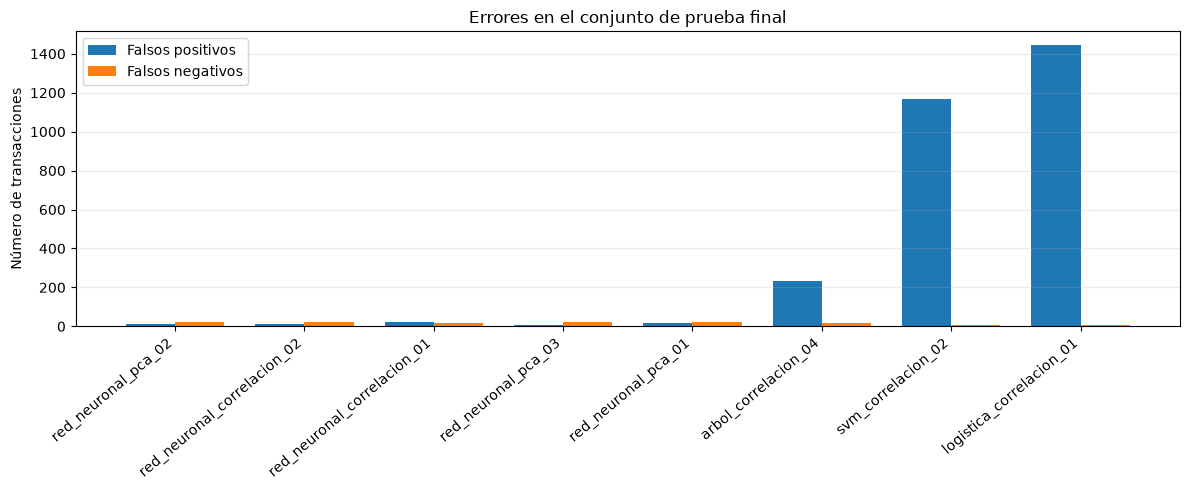

In [11]:
ver_errores = prueba[[
    "modelo_id", "falsos_positivos", "falsos_negativos",
    "precision_fraude", "sensibilidad_fraude"
]].copy()
display(ver_errores.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(prueba))
ancho = 0.38
ax.bar(x - ancho / 2, prueba["falsos_positivos"], ancho, label="Falsos positivos")
ax.bar(x + ancho / 2, prueba["falsos_negativos"], ancho, label="Falsos negativos")
ax.set_xticks(x, prueba["modelo_id"], rotation=40, ha="right")
ax.set_ylabel("Número de transacciones")
ax.set_title("Errores en el conjunto de prueba final")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretación: sensibilidad alta no siempre significa un mejor clasificador

En la ejecución original, la regresión logística detectó **91 de los 98 fraudes** (sensibilidad **92,86 %**), pero produjo **1.443 falsas alarmas** y una precisión de fraude de apenas **5,93 %**. El SVM lineal presentó un comportamiento parecido.

En cambio, el modelo seleccionado `red_neuronal_pca_02` detectó **76 fraudes**, dejó de identificar **22** y produjo solo **12 falsos positivos**. Su precisión de fraude fue **86,36 %**.

Por tanto, **detectar más fraudes no equivale automáticamente a mejorar el equilibrio de clasificación**. La elección dependerá de qué errores sean más costosos para la institución.

## 11. Matrices de confusión de la evaluación final

Comparamos la red neuronal seleccionada por CV con la regresión logística representante de su familia. Las matrices se construyen **directamente desde el CSV de prueba**, evitando volver a entrenar y asegurando que los conteos coincidan con la ejecución registrada.

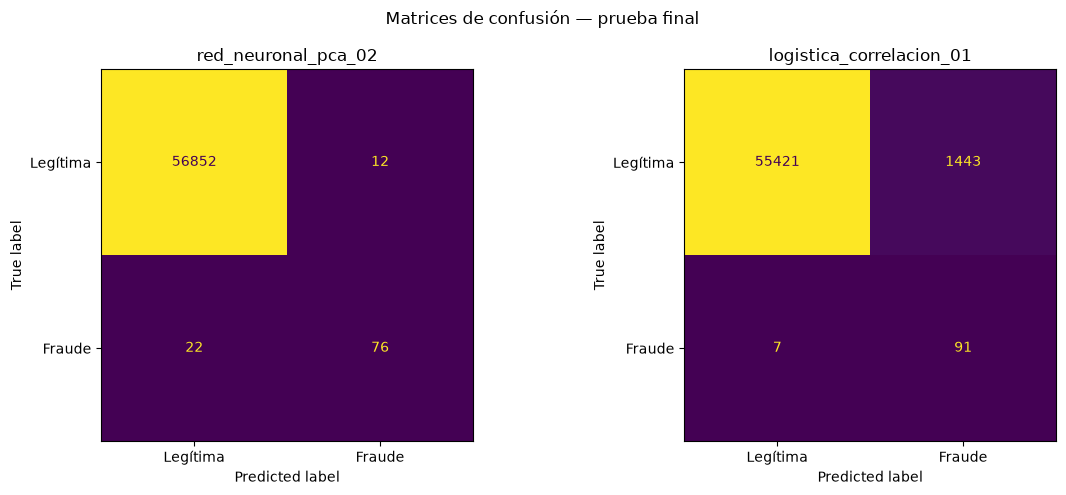

In [12]:
ids_matrices = ["red_neuronal_pca_02", "logistica_correlacion_01"]
filas = prueba.set_index("modelo_id")

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for eje, identificador in zip(ejes, ids_matrices):
    if identificador not in filas.index:
        eje.text(0.5, 0.5, f"No está en el CSV:\n{identificador}",
                 ha="center", va="center", transform=eje.transAxes)
        eje.axis("off")
        continue
    fila = filas.loc[identificador]
    matriz = np.array([
        [int(fila["verdaderos_negativos"]), int(fila["falsos_positivos"])],
        [int(fila["falsos_negativos"]), int(fila["verdaderos_positivos"])],
    ])
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Legítima", "Fraude"]
    ).plot(ax=eje, colorbar=False, values_format="d")
    eje.set_title(identificador)

fig.suptitle("Matrices de confusión — prueba final")
plt.tight_layout()
plt.show()

In [ ]:

from pathlib import Path
from IPython.display import display, Markdown

# Localizar la raíz del proyecto
directorio = Path.cwd().resolve()

RAIZ = (
    directorio.parent
    if directorio.name == "notebooks"
    else directorio
)

# Documento de discusión del punto 1
archivo = (
    RAIZ / "Discusión de resultados — Punto 1.txt"
)

# Leer el contenido
contenido = archivo.read_text(
    encoding="utf-8-sig"
)

# Mostrar como Markdown
display(
    Markdown(
        "---\n\n"
        + contenido.strip()
        + "\n\n---"
    )
)


## 12. Conclusiones del punto 1

### Hallazgos principales

1. **El desbalance extremo condicionó la evaluación.** Una exactitud alta habría podido ocultar un clasificador incapaz de identificar fraudes.
2. **Las redes neuronales dominaron el Top 5 de validación cruzada** bajo las configuraciones probadas. Su capacidad no lineal es una explicación posible, pero no demuestra superioridad universal.
3. **La regresión logística y el SVM lograron gran sensibilidad**, aunque generaron numerosas falsas alarmas; por ello, su F1 macro fue considerablemente menor.
4. **El modelo `red_neuronal_pca_02` fue seleccionado por validación cruzada**, no por el resultado del conjunto de prueba. Esto protege la independencia de la evaluación final.
5. **Los errores tienen consecuencias diferentes.** Una solución real debe equilibrar el fraude no detectado con el costo de revisar operaciones legítimas.

### Limitaciones

- El conjunto de prueba contiene solo 98 fraudes; las métricas de la clase minoritaria son sensibles a variaciones de pocos casos.
- Se probaron configuraciones concretas, no todas las arquitecturas y parámetros posibles.
- La evaluación utiliza la misma base de datos y una división específica; sería recomendable validar con datos más recientes o de otra fuente antes de un despliegue real.

**Conclusión general:** la red neuronal con PCA seleccionada mediante validación cruzada presentó un equilibrio favorable entre precisión y detección de fraude, pero su utilidad práctica dependerá del costo relativo de falsos positivos y falsos negativos.

## 13. Evidencia y reproducibilidad

Este notebook **no entrena de nuevo** los modelos. Sus resultados provienen de:

- `resultados/punto_1/validacion_cruzada.csv`: 32 configuraciones, promedios y desviaciones de tres folds.
- `resultados/punto_1/evaluacion_final/metricas_prueba_final.csv`: métricas y conteos definitivos del conjunto de prueba.
- `src/punto_1/analizar_top5.py`: procesamiento del ranking y Top 5.
- `src/punto_1/evaluacion_final.py`: selección de finalistas y evaluación reservada.

### Comandos originales utilizados

```powershell
python -m src.punto_1.analizar_seleccion
python -m src.punto_1.validacion_cruzada --modelo logistica
python -m src.punto_1.validacion_cruzada --modelo arbol
python -m src.punto_1.validacion_cruzada --modelo svm
python -m src.punto_1.validacion_cruzada --modelo red_neuronal
python -m src.punto_1.analizar_top5
python -m src.punto_1.evaluacion_final
```

**Para revisar el notebook**, basta con ejecutar sus celdas de arriba hacia abajo, siempre que estén presentes los CSV generados.